# Honolulu traffic incidents

Exploratory feature engineering for the included 194 incident reports dated January 23–24, 2026. The notebook parses timestamps, creates time and category features, and plots incident counts. Its severity flag is a type-based proxy; its top-ten-area flag is calculated from this same snapshot. Neither should be interpreted as a validated severity label or a prospective hotspot forecast. Run Jupyter from this project folder so `data/Traffic_Incidents.csv` resolves. No prediction model is trained or evaluated here.

ORIGINAL TRAFFIC INCIDENTS DATA LOADED
         Date         Time  ...             Location       Area
0  01/24/2026  09:56:22 AM  ...                  NaN     Nuuanu
1  01/24/2026  09:54:49 AM  ...         HONOKAI HALE    Kapolei
2  01/24/2026  09:47:29 AM  ...                  NaN   Downtown
3  01/24/2026  09:43:15 AM  ...                  NaN   Kapahulu
4  01/24/2026  09:40:24 AM  ...     WALMART MILILANI   Mililani
5  01/24/2026  09:37:33 AM  ...                  NaN     Kalihi
6  01/24/2026  09:08:28 AM  ...         H1E KUNIA ON    Waipahu
7  01/24/2026  09:06:49 AM  ...  MCDONALDS PEARL KAI       Aiea
8  01/24/2026  08:39:02 AM  ...           WAIANAE MS    Waianae
9  01/24/2026  08:30:04 AM  ...                  NaN  Ewa Beach

[10 rows x 6 columns]

Shape: (194, 6)
<class 'pandas.DataFrame'>
RangeIndex: 194 entries, 0 to 193
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Date      194 non-null    str  
 1   Time    

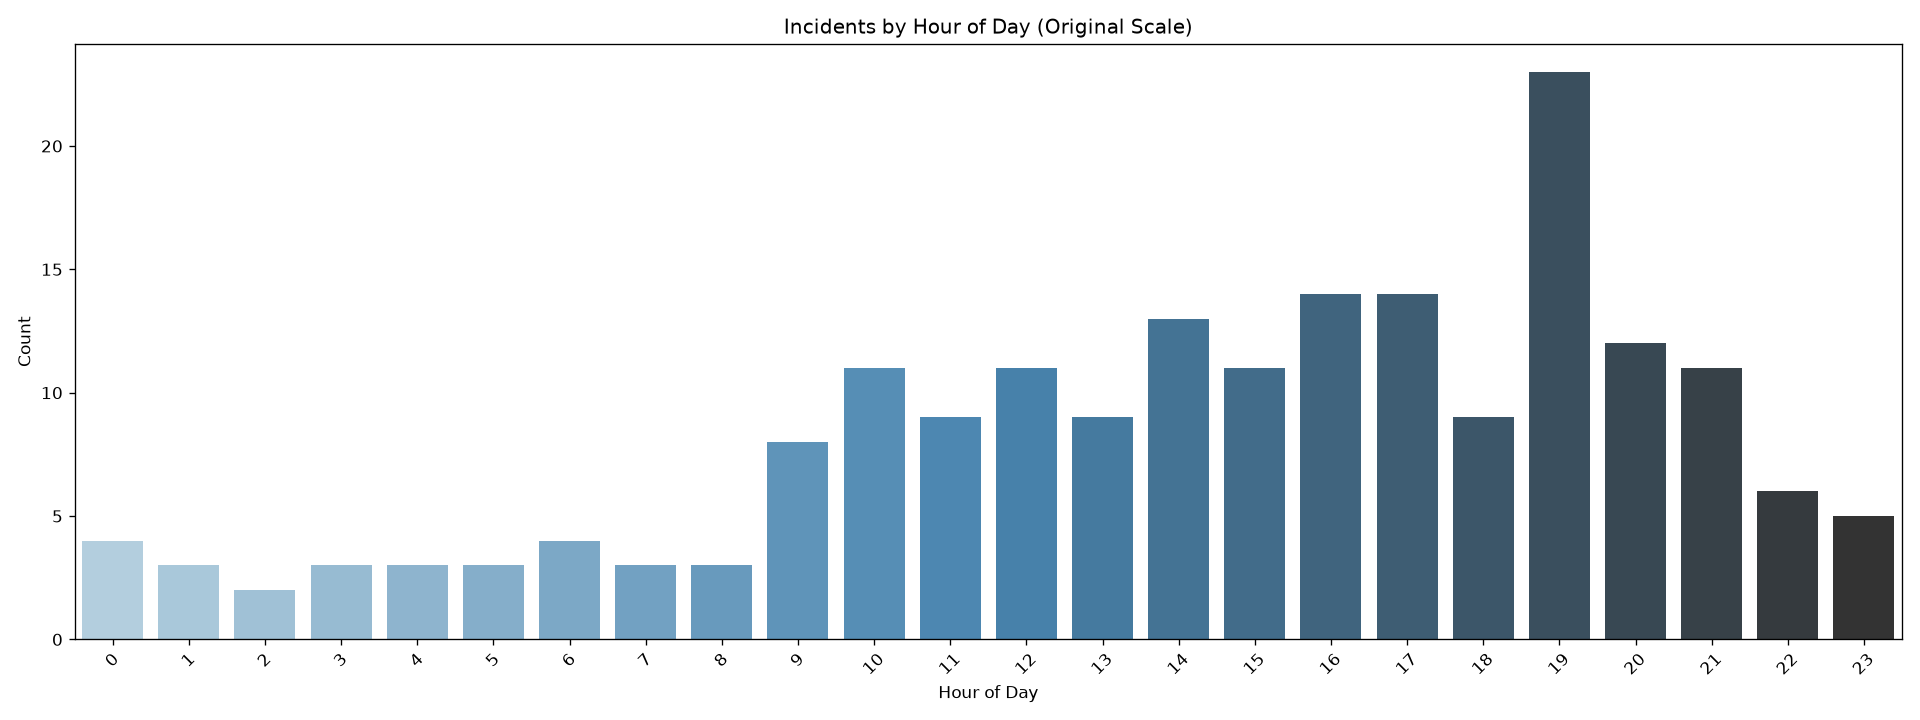

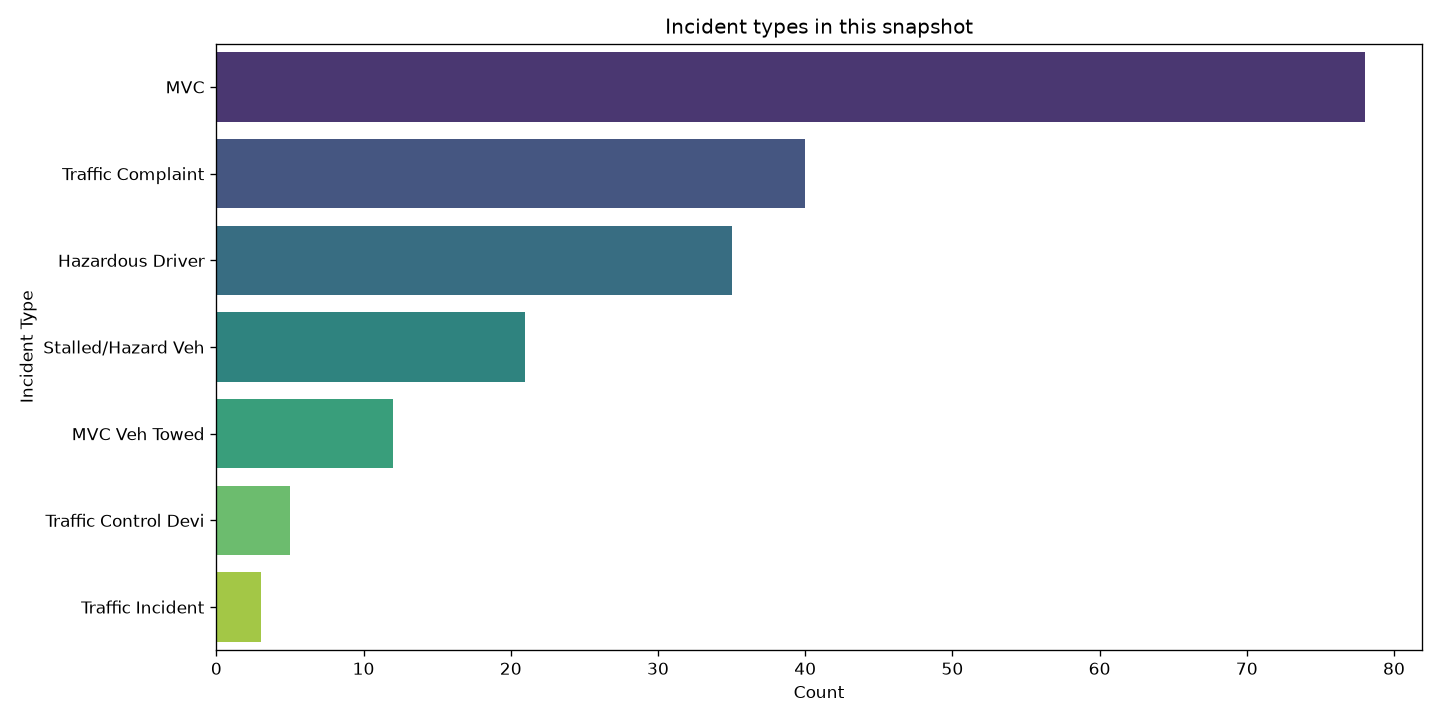

In [1]:
"""
Traffic Incidents Feature Engineering & Preprocessing Pipeline
Honolulu Traffic Incidents Dataset (Jan 23-24, 2026)
@author: https://github.com/DocOhms/machine-learning-portfolio
Dataset: Traffic_Incidents.csv (Honolulu Police/Traffic real-time reports)
Purpose: Clean, engineer, and prepare incident data for downstream ML tasks
         (e.g., incident type prediction, hotspot forecasting, severity modeling)
"""

# Import libraries
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, LabelEncoder
import matplotlib.pyplot as plt
import seaborn as sns

class TrafficIncidentsEngineering:
    def __init__(self):
        self.df = None
    
    def create_DFrame_from_csv(self, file_path="data/Traffic_Incidents.csv"):
        try:
            df = pd.read_csv(file_path)
            print("ORIGINAL TRAFFIC INCIDENTS DATA LOADED")
            print(df.head(10))
            print(f"\nShape: {df.shape}")
            df.info()
            self.df = df
        except FileNotFoundError:
            print(f"Error: The file '{file_path}' was not found. Run this notebook from the traffic-preprocessing project folder.")
        except Exception as e:
            print("An error occurred:", e)
    
    def Handle_Missing_Values(self):
        if self.df is None:
            print("Load data first!")
            return
        
        df = self.df
        print("\nMissing values before handling:")
        print(df.isnull().sum())
        
        # Minimal missing in this dataset, but handle safely
        df['Area'] = df['Area'].fillna('Unknown')
        df['Address'] = df['Address'].fillna('Unknown')
        df['Location'] = df['Location'].fillna('Unknown')
        
        # Combine Date + Time into proper datetime
        df['FullDateTime'] = pd.to_datetime(
            df['Date'] + ' ' + df['Time'],
            format='%m/%d/%Y %I:%M:%S %p',
            errors='coerce'
        )
        df = df.dropna(subset=['FullDateTime']).reset_index(drop=True)
        
        print("\nMISSING VALUES HANDLED & DATETIME COMBINED")
        print(df.head(10))
        self.df = df
    
    def Feature_Creation(self):
        if self.df is None:
            print("Load and clean data first!")
            return
        
        df = self.df
        
        # Time-based features
        df['Hour'] = df['FullDateTime'].dt.hour
        df['DayOfWeek'] = df['FullDateTime'].dt.day_name()
        df['IsWeekend'] = df['FullDateTime'].dt.day_of_week >= 5
        df['IsRushHour'] = df['Hour'].apply(lambda h: 1 if h in [6,7,8,9,16,17,18,19] else 0)
        
        # Incident severity proxy (simple heuristic)
        high_severity_types = ['MVC', 'MVC Veh Towed']
        df['IsHighSeverity'] = df['Type'].isin(high_severity_types).astype(int)
        
        # Area hotspot flag (top 10 areas get flag)
        top_areas = df['Area'].value_counts().head(10).index
        df['IsHotspotArea'] = df['Area'].isin(top_areas).astype(int)
        
        print("\nNEW FEATURES CREATED")
        print(df[['Type', 'Area', 'Hour', 'DayOfWeek', 'IsRushHour', 'IsHighSeverity', 'IsHotspotArea']].head(15))
        self.df = df
    
    def Feature_Transformation(self):
        if self.df is None:
            print("Complete previous steps first!")
            return
        
        df = self.df
        
        # Scaling numeric features
        scaler = StandardScaler()
        numeric_cols = ['Hour']
        df['Hour_scaled'] = scaler.fit_transform(df[numeric_cols]).ravel()
        
        # Label encoding categorical features
        le_type = LabelEncoder()
        le_area = LabelEncoder()
        le_day = LabelEncoder()
        
        df['Type_encoded'] = le_type.fit_transform(df['Type'])
        df['Area_encoded'] = le_area.fit_transform(df['Area'])
        df['DayOfWeek_encoded'] = le_day.fit_transform(df['DayOfWeek'])
        
        print("\nFEATURES SCALED & ENCODED")
        print(df[['Type_encoded', 'Area_encoded', 'DayOfWeek_encoded', 'Hour', 'Hour_scaled', 'IsRushHour']].head(10))
        self.df = df
    
    def Feature_Selection_and_Exploration(self):
        if self.df is None:
            print("Complete previous steps first!")
            return
    
        df = self.df
    
        # Drop raw text columns not needed for modeling
        cols_to_drop = ['Date', 'Time', 'Address', 'Location', 'FullDateTime']
        df_model = df.drop(columns=cols_to_drop)
    
        # Correlation check example
        corr_matrix = df_model.select_dtypes(include=[np.number]).corr()
        print("\nCORRELATION MATRIX (numeric features)")
        print(corr_matrix)
    
        # Improved visualization: Incidents by Hour (fixed overlapping labels + deprecation warning)
        plt.figure(figsize=(16, 6))
        sns.countplot(
            data=df,
            x='Hour',
            hue='Hour',                  # Assign x to hue to use palette correctly
            order=sorted(df['Hour'].unique()),
            palette='Blues_d',
            legend=False                 # Hide unnecessary legend
        )
        plt.title('Incidents by Hour of Day (Original Scale)')
        plt.xlabel('Hour of Day')
        plt.ylabel('Count')
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()
    
        # Top 10 Incident Types (fixed deprecation warning)
        plt.figure(figsize=(12, 6))
        top_types = df['Type'].value_counts().head(10)
        sns.barplot(
            x=top_types.values,
            y=top_types.index,
            hue=top_types.index,         # Assign y to hue to use palette correctly
            palette='viridis',
            legend=False                 # Hide unnecessary legend
        )
        plt.title('Incident types in this snapshot')
        plt.xlabel('Count')
        plt.ylabel('Incident Type')
        plt.tight_layout()
        plt.show()
    
        print("\nENGINEERED INCIDENT FEATURE TABLE")
        print(df_model.head(10))
        print(f"\nFinal shape: {df_model.shape}")
        self.df_final = df_model

# ---------------------------- Class Driver ----------------------------
incidents = TrafficIncidentsEngineering()
incidents.create_DFrame_from_csv("data/Traffic_Incidents.csv")
incidents.Handle_Missing_Values()
incidents.Feature_Creation()
incidents.Feature_Transformation()
incidents.Feature_Selection_and_Exploration()